In [1]:
import os
import utils_data_RF
import dataset_RF
import importlib
import xarray as xr
import pandas
import numpy as np
from data_functions.utils_data import plot_label
import geopandas as gpd

## Random forest
Data :
- should contain spectrale indices (3)
- not need for scaling
- should be of shape (n_samples= batch, n_features= (10+3)*T)
- data per zone (1)
- time management (resample on a commune fictive grid) (2)
Model :
- 1 model per eco zone

### Dataset

In [3]:
zone = 1
path_s2_data = os.path.join(
    "/home/hkerino/Documents/nextoso-dataset/data/10m/s2", str(zone)
)
path_label = "/home/hkerino/Documents/nextoso-dataset/data/10m/labels"
folders = [1]

In [4]:
importlib.reload(utils_data_RF)

T0 = "2020-01-15"
T_fin = "2020-12-31"

temp_grid = pandas.date_range(start=T0, end=T_fin, freq="16D")

s2_list = []
label_list = []
for i in folders:
    path_s2 = os.path.join(path_s2_data, f"fold_{str(i)}")

    s2_nc_files = [f for f in os.listdir(path_s2) if f.endswith(".nc")]
    for s2_nc_file in s2_nc_files:
        # s2
        with xr.open_dataset(os.path.join(path_s2, s2_nc_file)) as s2_data:
            s2_data = utils_data_RF.remove_invalid(s2_data)
            s2 = utils_data_RF.s2_spectrale_indice(s2_data)
            s2_list.append(
                s2[
                    [
                        "B2",
                        "B3",
                        "B4",
                        "B5",
                        "B6",
                        "B7",
                        "B8",
                        "B8A",
                        "B11",
                        "B12",
                        "ndvi",
                        "ndwi",
                        "brightness",
                    ]
                ]
            )

        # Label
        file_id = s2_nc_file.split("_")[1].split(".")[0]
        path_label_file = os.path.join(path_label, f"label_{file_id}.nc")
        with xr.open_dataset(path_label_file) as label_data:
            label_numpy = label_data["max_class_1"].data  # NumPy
            label_numpy = np.where(label_numpy == -1, 0, label_numpy)  # Replace -1 by 0
            label_list.append(label_numpy)
Label = np.stack(label_list)

In [5]:
d = utils_data_RF.interpolate(s2_list=s2_list, grid=temp_grid)

In [6]:
print("DATA shape", d.shape)
print("LABEL shape", Label.shape)

DATA shape (106, 22, 13, 128, 128)
LABEL shape (106, 128, 128)


In [7]:
b, t, c, h, w = d.shape
X = d.transpose(0, 3, 4, 1, 2).reshape(-1, t * c)
Y = Label.reshape(-1)

print("X shape ", X.shape)
print("Y shape ", Y.shape)

X shape  (1736704, 286)
Y shape  (1736704,)


In [28]:
importlib.reload(dataset_RF)
(Y, id) = dataset_RF.create_dataset(
    label_only=True, return_id=True, zone=4, folders=[5]
)

In [29]:
id

array(['0057', '0064', '0125', '0135', '0150', '0178', '0197', '0275',
       '0393', '0395', '0423', '0470', '0480', '0523', '0527', '0540',
       '0547', '0586', '0664', '0672', '0684', '0746', '0752', '0782',
       '0830', '0913', '0918', '0924', '1012', '1022', '1026', '1038',
       '1061', '1095', '1105', '1109', '1111', '1113', '1201', '1265',
       '1371', '1383', '1385', '1417', '1432', '1465', '1473', '1561',
       '1582', '1630', '1631', '1645', '1669', '1692', '1726', '1780',
       '1782', '1783', '1827', '1839', '1892', '1896', '1945', '1964',
       '1976', '1998', '2000', '2002', '2016', '2073', '2123', '2146',
       '2202', '2223', '2251', '2288', '2323', '2337', '2353', '2360',
       '2444', '2460', '2467', '2472', '2488', '2490', '2496', '2507',
       '2530', '2541', '2553', '2597', '2626', '2637', '2647', '2660',
       '2723', '2731', '2739', '2747', '2779', '2834', '2913', '2927',
       '2980', '2988', '2999', '3039', '3072', '3087', '3088', '3190',
      

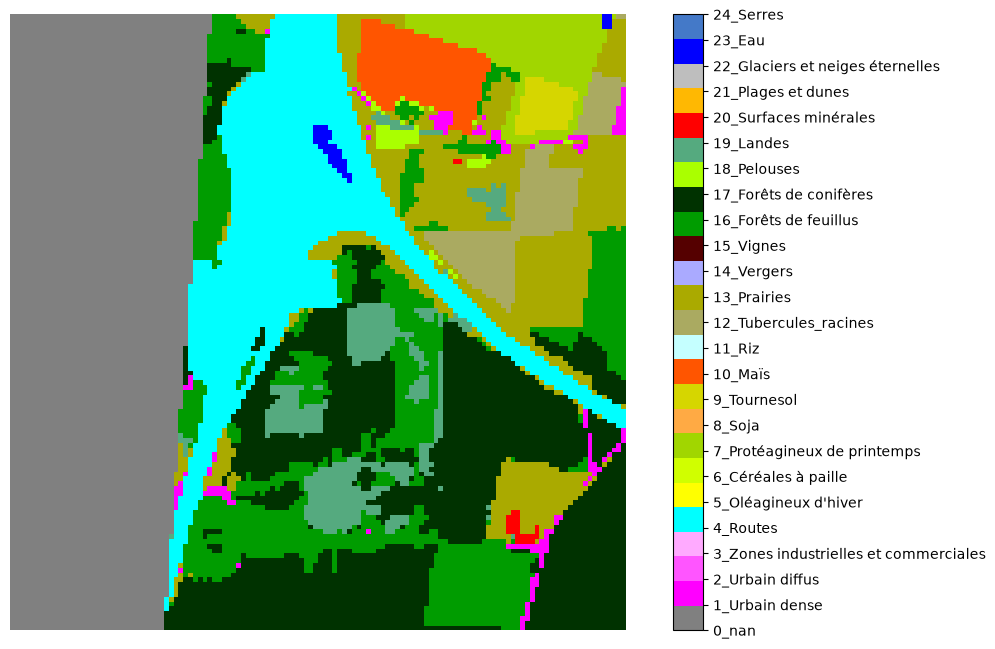

In [30]:
plot_label(Y[np.where(id == "0197")[0][0]])

### Classifier

In [10]:
from sklearn.ensemble import RandomForestClassifier

classifier = RandomForestClassifier()
classifier.fit(X[0:100000, :], Y[0:100000])

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [ ]:
classifier.predict()

In [9]:
preds_4 = np.load(
    "/home/hkerino/Documents/next_oso/logs/RF/2026-07-17/fold_1/zone_eco_4/y_pred.npy"
)
trues_4 = np.load(
    "/home/hkerino/Documents/next_oso/logs/RF/2026-07-17/fold_1/zone_eco_4/y_true.npy"
)

preds_6 = np.load(
    "/home/hkerino/Documents/next_oso/logs/RF/2026-07-17/fold_1/zone_eco_6/y_pred.npy"
)
trues_6 = np.load(
    "/home/hkerino/Documents/next_oso/logs/RF/2026-07-17/fold_1/zone_eco_6/y_true.npy"
)

In [14]:
preds = np.concatenate([preds_4, preds_6], axis=0)
trues = np.concatenate([trues_4, trues_6], axis=0)

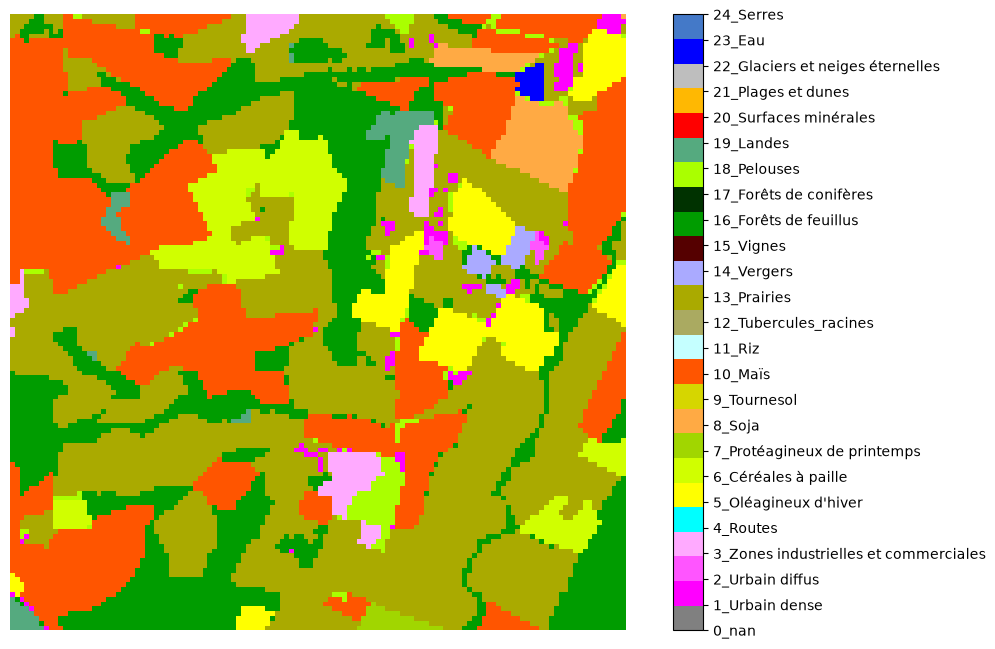

In [18]:
plot_label(trues[81])

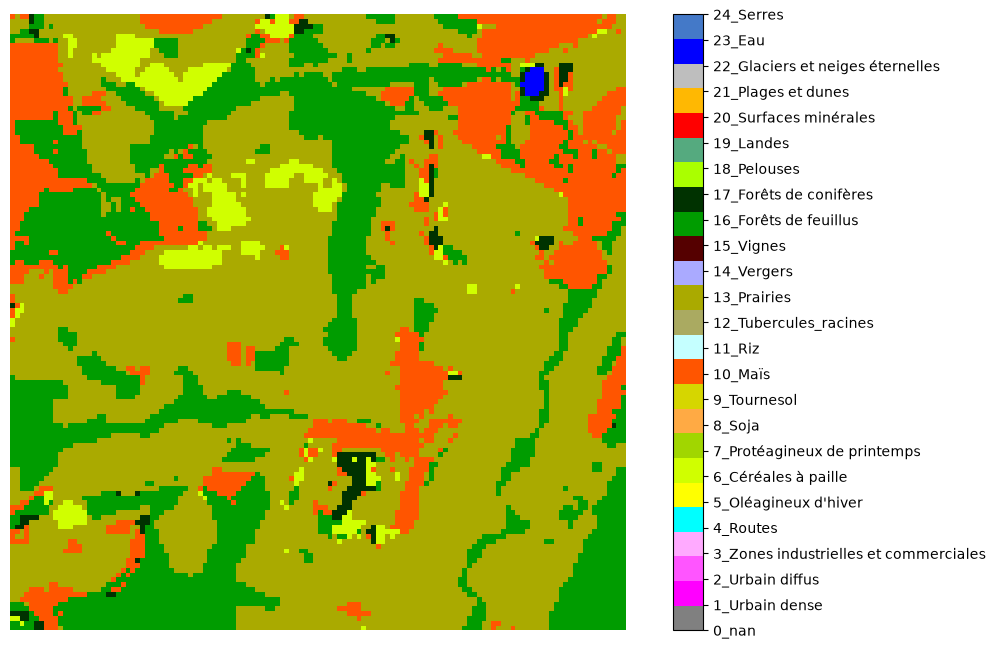

In [19]:
plot_label(preds[81])

## On PASTIS

In [5]:
s2_no = xr.open_dataset(
    "/home/hkerino/Documents/nextoso-dataset/data/10m/s2/1/fold_1/s2_0002.nc"
)

In [6]:
s2_no

<xarray.Dataset> Size: 35MB
Dimensions:      (time: 97, y: 128, x: 128)
Coordinates:
  * time         (time) datetime64[ns] 776B 2020-01-01T10:59:07 ... 2020-12-3...
  * y            (y) float32 512B 6.194e+06 6.194e+06 ... 6.193e+06 6.193e+06
  * x            (x) float32 512B 5.31e+05 5.31e+05 ... 5.323e+05 5.323e+05
Data variables:
    B2           (time, y, x) int16 3MB ...
    B3           (time, y, x) int16 3MB ...
    B4           (time, y, x) int16 3MB ...
    B5           (time, y, x) int16 3MB ...
    B6           (time, y, x) int16 3MB ...
    B7           (time, y, x) int16 3MB ...
    B8           (time, y, x) int16 3MB ...
    B8A          (time, y, x) int16 3MB ...
    B11          (time, y, x) int16 3MB ...
    B12          (time, y, x) int16 3MB ...
    S2_mask      (time, y, x) int16 3MB ...
    spatial_ref  int64 8B ...
Attributes:
    year:        2020
    id:          D009_2019-Z8_NN_T31TCH
    size:        128
    resolution:  10

In [2]:
s2 = np.load("/home/hkerino/Documents/PASTIS/DATA_S2/S2_10000.npy")

In [3]:
s2.shape

(43, 10, 128, 128)

In [51]:
s2[0].shape

(10, 128, 128)

In [9]:
metadata = gpd.read_file("/home/hkerino/Documents/PASTIS/metadata.geojson")

In [12]:
metadata

,Fold,ID_PATCH,N_Parcel,Parcel_Cover,TILE,dates-S2,id,geometry
0,1,10000,119,0.808032,t30uxv,"{'0': 20180924, '1': 20180929, '2': 20181004, ...",10000,"MULTIPOLYGON (((391504.736 6956805.915, 392781..."
1,2,10001,111,0.501986,t30uxv,"{'0': 20180924, '1': 20180929, '2': 20181004, ...",10001,"MULTIPOLYGON (((367628.562 6880296.822, 368905..."
2,4,10002,131,0.638722,t30uxv,"{'0': 20180924, '1': 20180929, '2': 20181004, ...",10002,"MULTIPOLYGON (((388950.375 6957003.181, 390227..."
3,5,10003,75,0.866824,t30uxv,"{'0': 20180924, '1': 20180929, '2': 20181004, ...",10003,"MULTIPOLYGON (((455228.326 6917189.74, 456504...."
4,4,10004,46,0.204906,t30uxv,"{'0': 20180924, '1': 20180929, '2': 20181004, ...",10004,"MULTIPOLYGON (((364779.509 6910052.243, 366056..."
...,...,...,...,...,...,...,...,...
2428,2,40558,33,0.783991,t32ulu,"{'0': 20180917, '1': 20180922, '2': 20180927, ...",40558,"MULTIPOLYGON (((977680.878 6836058.796, 978956..."
2429,5,40559,24,0.129896,t32ulu,"{'0': 20180917, '1': 20180922, '2': 20180927, ...",40559,"MULTIPOLYGON (((1018204.4 6759608.309, 1019480..."
2430,3,40560,7,0.255358,t32ulu,"{'0': 20180917, '1': 20180922, '2': 20180927, ...",40560,"MULTIPOLYGON (((1007714.487 6812700.875, 10089..."
2431,3,40561,5,0.054305,t32ulu,"{'0': 20180917, '1': 20180922, '2': 20180927, ...",40561,"MULTIPOLYGON (((1002310.153 6766088.52, 100358..."


In [67]:
folders = [1, 2, 3]
tiles = ["t30uxv", "t31tfj", "t31tfm", "t32ulu"]
ids = list(
    metadata[(metadata["Fold"].isin(folders)) & (metadata["TILE"] == tiles[0])]["id"]
)

In [61]:
grid_time = pandas.date_range(start="2018-09-01", end="2019-11-30", freq="10D")

In [69]:
id = int(ids[0])
dates = metadata[metadata["ID_PATCH"] == id]["dates-S2"]

In [76]:
list(dates[0].values())

[20180924,
 20180929,
 20181004,
 20181009,
 20181019,
 20181024,
 20181029,
 20181108,
 20181113,
 20181118,
 20181123,
 20190117,
 20190122,
 20190216,
 20190221,
 20190226,
 20190313,
 20190328,
 20190412,
 20190422,
 20190427,
 20190512,
 20190527,
 20190601,
 20190606,
 20190621,
 20190626,
 20190701,
 20190706,
 20190711,
 20190716,
 20190731,
 20190810,
 20190815,
 20190820,
 20190825,
 20190830,
 20190904,
 20190914,
 20190919,
 20190924,
 20191009,
 20191019]

In [77]:
grid_time

DatetimeIndex(['2018-09-01', '2018-09-11', '2018-09-21', '2018-10-01',
               '2018-10-11', '2018-10-21', '2018-10-31', '2018-11-10',
               '2018-11-20', '2018-11-30', '2018-12-10', '2018-12-20',
               '2018-12-30', '2019-01-09', '2019-01-19', '2019-01-29',
               '2019-02-08', '2019-02-18', '2019-02-28', '2019-03-10',
               '2019-03-20', '2019-03-30', '2019-04-09', '2019-04-19',
               '2019-04-29', '2019-05-09', '2019-05-19', '2019-05-29',
               '2019-06-08', '2019-06-18', '2019-06-28', '2019-07-08',
               '2019-07-18', '2019-07-28', '2019-08-07', '2019-08-17',
               '2019-08-27', '2019-09-06', '2019-09-16', '2019-09-26',
               '2019-10-06', '2019-10-16', '2019-10-26', '2019-11-05',
               '2019-11-15', '2019-11-25'],
              dtype='datetime64[ns]', freq='10D')

In [6]:
from pastis.RF_pastis import create_RF_dataset_PASTIS

(X, Y, ids) = create_RF_dataset_PASTIS()

/home/hkerino/Documents/next_oso/pastis/RF_pastis.py:22: RuntimeWarning: invalid value encountered in sqrt
  brightness = np.sqrt(np.sum(s2**2, axis=1))


ValueError: time data "{'0': 20180924, '1': 20180929, '2': 20181004, '3': 20181009, '4': 20181019, '5': 20181024, '6': 20181029, '7': 20181108, '8': 20181113, '9': 20181118, '10': 20181123, '11': 20190117, '12': 20190122, '13': 20190216, '14': 20190221, '15': 20190226, '16': 20190313, '17': 20190328, '18': 20190412, '19': 20190422, '20': 20190427, '21': 20190512, '22': 20190527, '23': 20190601, '24': 20190606, '25': 20190621, '26': 20190626, '27': 20190701, '28': 20190706, '29': 20190711, '30': 20190716, '31': 20190731, '32': 20190810, '33': 20190815, '34': 20190820, '35': 20190825, '36': 20190830, '37': 20190904, '38': 20190914, '39': 20190919, '40': 20190924, '41': 20191009, '42': 20191019}" doesn't match format "%Y%m%d", at position 0. You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format wil